# F3_02 · Eficiencia y clase de proporciones (Fase 3)

**Curso:** MCDI500 · Programación para la Ciencia de Datos · **Grupo 2**
**Proyecto:** Colecistectomía en grupos de riesgo de cáncer de vesícula, La Araucanía 2022

## Objetivo
Calcular la proporción de egresos por colelitiasis con colecistectomía, por grupo de riesgo y provincia,
y **comparar cuatro implementaciones** del mismo cálculo (incluida una **recursiva**) con mediciones
reproducibles (`timeit`, `tracemalloc`) para justificar cuál se adopta, considerando complejidad
temporal y espacial. La tabla final incorpora el **intervalo de confianza de Wilson (95 %)** de cada proporción.

## Cómo se integra con las fases anteriores
- **Entrada:** `data/processed/egresos_araucania_k80_transformado.csv`, generado en F2_03. **Este notebook no vuelve a transformar los datos**; solo los lee.
- **Código:** la clase de proporciones vive en `src/proporciones.py` (módulo reutilizable).
- **Salida:** la tabla de proporciones con su IC de Wilson y la estrategia elegida, que alimentarán la Fase 4.

## Contenido
1. Configuración y entorno · 2. Carga del conjunto transformado · 3. Diseño de clases (POO, con recursividad)
4. Validación: caso normal, límite y excepciones · 5. Metodología de medición · 6. Resultados
7. Interpretación y elección · 8. Resultado final con IC de Wilson · 9. Egresos excluidos (*) · 10. Conclusiones

## 1. Configuración y entorno
Las rutas se construyen desde la raíz del proyecto, de modo que el notebook funciona al abrirse desde la carpeta `F3/`. Se registran las versiones para que las mediciones sean reproducibles.

In [1]:
import sys, platform, timeit, tracemalloc, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if RAIZ.name.startswith("F"):
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

from proporciones import (Columnas, CalculadorBase, CalcBucle, CalcPandas,
                          CalcNumpy, CalcRecursivo, ESTRATEGIAS, wilson)

RUTA = RAIZ / "data" / "processed" / "egresos_araucania_k80_transformado.csv"

print("Python :", platform.python_version(), "|", platform.system(), platform.machine())
print("pandas :", pd.__version__, "| numpy:", np.__version__)
print("Entrada:", RUTA)

Python : 3.14.6 | Darwin arm64
pandas : 3.0.3 | numpy: 2.4.6
Entrada: /Users/connie/Downloads/proyecto-grupo2-mcdi500-main/data/processed/egresos_araucania_k80_transformado.csv


## 2. Carga del conjunto transformado (salida de F2_03)
Se leen solo las columnas necesarias. La clase `Columnas` ya trae por defecto los nombres reales
de F2_03 (`PROVINCIA_RESIDENCIA`, `FLAG_COLECISTECTOMIA`, `GRUPO_RIESGO_*`), por lo que no hay que indicarlos a mano.

In [2]:
COLS = Columnas()          # nombres reales de F2_03 por defecto
print("Columnas requeridas:", COLS.requeridas())

df = pd.read_csv(RUTA, usecols=list(COLS.requeridas()))
print("Filas y columnas:", df.shape)
print(df.dtypes.to_string())
df.head()

Columnas requeridas: ('PROVINCIA_RESIDENCIA', 'FLAG_COLECISTECTOMIA', 'GRUPO_RIESGO_MUJER', 'GRUPO_RIESGO_ETNIA', 'GRUPO_RIESGO_40_49')
Filas y columnas: (3789, 5)
PROVINCIA_RESIDENCIA     str
GRUPO_RIESGO_MUJER      bool
GRUPO_RIESGO_ETNIA      bool
GRUPO_RIESGO_40_49      bool
FLAG_COLECISTECTOMIA    bool


,PROVINCIA_RESIDENCIA,GRUPO_RIESGO_MUJER,GRUPO_RIESGO_ETNIA,GRUPO_RIESGO_40_49,FLAG_COLECISTECTOMIA
0,Cautín,False,False,False,True
1,Cautín,False,False,False,True
2,Malleco,False,False,False,False
3,Cautín,True,False,False,True
4,Malleco,False,False,False,True


In [3]:
assert len(df) == 3789, f"Se esperaban 3.789 egresos y hay {len(df)}"
assert int(df[COLS.flag].sum()) == 3056, "La marca de colecistectomía no coincide con F2_04"
assert df[COLS.provincia].isna().sum() == 0, "Hay egresos sin provincia"
print("Egresos:", len(df), "| con colecistectomía:", int(df[COLS.flag].sum()),
      f"({df[COLS.flag].mean():.1%})")
print(df[COLS.provincia].value_counts().to_string())

Egresos: 3789 | con colecistectomía: 3056 (80.7%)
PROVINCIA_RESIDENCIA
Cautín     3017
Malleco     772


## 3. Diseño de clases (POO, con recursividad)

```
                 CalculadorBase  (abstracta)
                 ├─ __init__(df, columnas)   valida y guarda el DataFrame (atributo protegido)
                 ├─ calcular()               plantilla: tabla estándar + IC de Wilson
                 ├─ proporcion_global()
                 └─ _contar()  «abstracto»   cada estrategia lo implementa
                      ▲
        ┌─────────────┼───────────────┬────────────────────┐
    CalcBucle     CalcPandas      CalcNumpy        CalcRecursivo
                                                 (divide y vencerás)
```

| Principio / patrón | Dónde se aplica |
|---|---|
| **Encapsulamiento** | El DataFrame se guarda en `_df` y se valida en el constructor (columnas requeridas y provincia sin nulos). |
| **Herencia** | Las cuatro estrategias reutilizan validación, formato de salida y `proporcion_global()` de la base. |
| **Polimorfismo** | Todas se usan con `.calcular()`; el código que las compara no sabe cuál es cuál. |
| **Recursividad** | `CalcRecursivo` parte las filas en mitades, cuenta cada mitad por recursión y combina (divide y vencerás). |
| **Template Method** | `calcular()` fija el formato de salida y delega el conteo a `_contar()`. |
| **Strategy** | Cada clase es una estrategia intercambiable de conteo. |

In [4]:
for cls in ESTRATEGIAS:
    print(f"{cls.__name__:<14} hereda de {cls.__bases__[0].__name__:<15} -> {cls.nombre}")
CalcNumpy(df, COLS).calcular().head()

CalcBucle      hereda de CalculadorBase  -> Bucle Python
CalcPandas     hereda de CalculadorBase  -> pandas groupby
CalcNumpy      hereda de CalculadorBase  -> NumPy máscaras
CalcRecursivo  hereda de CalculadorBase  -> Recursivo (divide y vencerás)


,grupo,provincia,en_grupo,egresos,con_colecistectomia,proporcion,ic95_inf,ic95_sup
0,GRUPO_RIESGO_40_49,Cautín,False,2496,2001,0.801683,0.785581,0.816857
1,GRUPO_RIESGO_40_49,Cautín,True,521,465,0.892514,0.862987,0.916295
2,GRUPO_RIESGO_40_49,Malleco,False,645,490,0.759690,0.725240,0.791065
3,GRUPO_RIESGO_40_49,Malleco,True,127,100,0.787402,0.708350,0.849576
4,GRUPO_RIESGO_ETNIA,Cautín,False,2384,1967,0.825084,0.809314,0.839807


## 4. Validación técnica: caso normal, casos límite y excepciones
**Caso normal:** las cuatro estrategias deben producir exactamente la misma tabla, y la proporción global debe coincidir con la validada en F2 (3.056 / 3.789).

In [5]:
calculadores = {cls.nombre: cls(df, COLS) for cls in ESTRATEGIAS}
tablas = {nombre: c.calcular() for nombre, c in calculadores.items()}

base = tablas["Bucle Python"]
for nombre, t in tablas.items():
    pd.testing.assert_frame_equal(base, t, check_dtype=False)
    print(f"OK  {nombre:<28} igual a la versión de referencia")

glob = {n: c.proporcion_global() for n, c in calculadores.items()}
assert all(abs(v - 3056 / 3789) < 1e-12 for v in glob.values())
print(f"OK  proporción global = {3056/3789:.4f} (3.056 / 3.789) en las cuatro versiones")

OK  Bucle Python                 igual a la versión de referencia
OK  pandas groupby               igual a la versión de referencia
OK  NumPy máscaras               igual a la versión de referencia
OK  Recursivo (divide y vencerás) igual a la versión de referencia
OK  proporción global = 0.8065 (3.056 / 3.789) en las cuatro versiones


**Casos límite:** un solo egreso, un grupo de riesgo sin ningún miembro y un conjunto vacío. Se usa el **nombre real** de la columna de grupo (`COLS.grupos[0]`), no un literal, para que la comprobación sea efectiva.

In [6]:
# 1) Un solo egreso
uno = df.iloc[[0]].reset_index(drop=True)
for cls in ESTRATEGIAS:
    t = cls(uno, COLS).calcular()
    assert t["egresos"].sum() == 3 * 1          # 3 grupos, 1 egreso cada uno
print("OK  un solo egreso: las 4 versiones coinciden y suman 3 filas de conteo")

# 2) Grupo de riesgo sin miembros (columna real, no un literal)
col_mujer = COLS.grupos[0]                       # 'GRUPO_RIESGO_MUJER'
sin_mujeres = df.assign(**{col_mujer: False})
tablas_lim = [cls(sin_mujeres, COLS).calcular() for cls in ESTRATEGIAS]
for t in tablas_lim[1:]:
    pd.testing.assert_frame_equal(tablas_lim[0], t, check_dtype=False)
fila_mujer = tablas_lim[0].query("grupo == @col_mujer and en_grupo")
assert fila_mujer.empty, "No debería haber filas de mujeres cuando el grupo está vacío"
print(f"OK  grupo '{col_mujer}' sin miembros: no genera fila ni divide por cero")

# 3) Conjunto vacío
vacio = df.iloc[0:0]
for cls in ESTRATEGIAS:
    c = cls(vacio, COLS)
    assert c.calcular().empty and np.isnan(c.proporcion_global())
print("OK  conjunto vacío: tabla vacía y proporción global NaN")

OK  un solo egreso: las 4 versiones coinciden y suman 3 filas de conteo
OK  grupo 'GRUPO_RIESGO_MUJER' sin miembros: no genera fila ni divide por cero
OK  conjunto vacío: tabla vacía y proporción global NaN


**Excepciones:** entradas inválidas deben fallar con un mensaje claro.

In [7]:
def esperar(excepcion, funcion, descripcion):
    try:
        funcion()
    except excepcion as e:
        print(f"OK  {descripcion}\n      -> {type(e).__name__}: {e}")
    else:
        raise AssertionError(f"No se lanzó {excepcion.__name__}: {descripcion}")

esperar(KeyError, lambda: CalcPandas(df.drop(columns=[COLS.flag]), COLS),
        "falta la columna de colecistectomía")
esperar(ValueError, lambda: CalcNumpy(df.assign(**{COLS.provincia: df[COLS.provincia].where(df.index > 0)}), COLS),
        "hay un egreso sin provincia")
esperar(TypeError, lambda: CalculadorBase(df, COLS),
        "la clase base abstracta no se puede instanciar")

OK  falta la columna de colecistectomía
      -> KeyError: "CalcPandas: faltan las columnas ['FLAG_COLECISTECTOMIA']."
OK  hay un egreso sin provincia
      -> ValueError: CalcNumpy: hay egresos sin provincia asignada.
OK  la clase base abstracta no se puede instanciar
      -> TypeError: Can't instantiate abstract class CalculadorBase without an implementation for abstract method '_contar'


## 5. Metodología de medición
- **Herramienta formal:** `timeit.Timer`. `autorange()` elige el número de llamadas por medición y `repeat()` registra 5 repeticiones; se reporta el **mínimo** (el menos contaminado por otros procesos), más media y desviación.
- **Qué se mide:** solo `calcular()`.
- **Escalamiento:** el conjunto real es pequeño (3.789 egresos); se repite ×1, ×10 y ×100 (hasta 378.900 filas) para observar cómo crece el tiempo con *n*.
- **Memoria:** `tracemalloc` registra la memoria retenida tras construir el objeto y el pico durante `calcular()`.

### Complejidad teórica esperada
| Versión | Tiempo | Espacio adicional |
|---|---|---|
| Bucle Python | O(n·g) | O(n) listas internas |
| pandas groupby | O(n·g) | O(n) interno del agrupamiento |
| NumPy máscaras | O(n·g·p) | O(n) por máscara |
| Recursivo | O(n·g) (más la pila O(log n)) | O(n) + pila de recursión |

In [8]:
FACTORES = (1, 10, 100)
REPETICIONES = 5

def medir(cls, datos):
    gc.collect()
    tracemalloc.start()
    obj = cls(datos, COLS)
    retenida, _ = tracemalloc.get_traced_memory()
    tracemalloc.reset_peak()
    obj.calcular()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    timer = timeit.Timer(obj.calcular)
    numero, _ = timer.autorange()
    tiempos = np.array(timer.repeat(repeat=REPETICIONES, number=numero)) / numero
    return {"estrategia": cls.nombre, "n": len(datos),
            "min_ms": tiempos.min() * 1e3, "media_ms": tiempos.mean() * 1e3,
            "desv_ms": tiempos.std(ddof=1) * 1e3,
            "repr_KiB": retenida / 1024, "pico_KiB": pico / 1024}

filas = []
for k in FACTORES:
    datos = pd.concat([df] * k, ignore_index=True)
    for cls in ESTRATEGIAS:
        filas.append(medir(cls, datos))
res = pd.DataFrame(filas)
res.round(3)

,estrategia,n,min_ms,media_ms,desv_ms,repr_KiB,pico_KiB
0,Bucle Python,3789,2.325,2.334,0.007,395.821,423.667
1,pandas groupby,3789,2.397,2.461,0.064,23.918,339.297
2,NumPy máscaras,3789,0.656,0.661,0.008,306.613,346.584
3,Recursivo (divide y vencerás),3789,2.336,2.380,0.032,395.689,429.763
4,Bucle Python,37890,19.053,19.137,0.054,3857.411,3886.008
5,pandas groupby,37890,4.936,4.994,0.040,156.547,2739.849
6,NumPy máscaras,37890,1.807,1.846,0.022,2968.777,3239.484
7,Recursivo (divide y vencerás),37890,19.328,20.296,1.385,3856.185,3897.186
8,Bucle Python,378900,194.067,199.848,4.515,38472.503,38501.100
9,pandas groupby,378900,38.022,44.094,5.153,1488.609,24950.293


## 6. Resultados

In [9]:
tiempo = res.pivot(index="n", columns="estrategia", values="min_ms").round(3)
print("Tiempo mínimo por llamada a calcular() [ms]")
display(tiempo)

memoria = res.pivot(index="n", columns="estrategia", values="pico_KiB").round(1)
print("Pico de memoria durante calcular() [KiB]")
display(memoria)

Tiempo mínimo por llamada a calcular() [ms]


estrategia,Bucle Python,NumPy máscaras,Recursivo (divide y vencerás),pandas groupby
n,,,,
3789,2.325,0.656,2.336,2.397
37890,19.053,1.807,19.328,4.936
378900,194.067,13.677,185.048,38.022


Pico de memoria durante calcular() [KiB]


estrategia,Bucle Python,NumPy máscaras,Recursivo (divide y vencerás),pandas groupby
n,,,,
3789,423.7,346.6,429.8,339.3
37890,3886.0,3239.5,3897.2,2739.8
378900,38501.1,32283.2,38515.2,24950.3


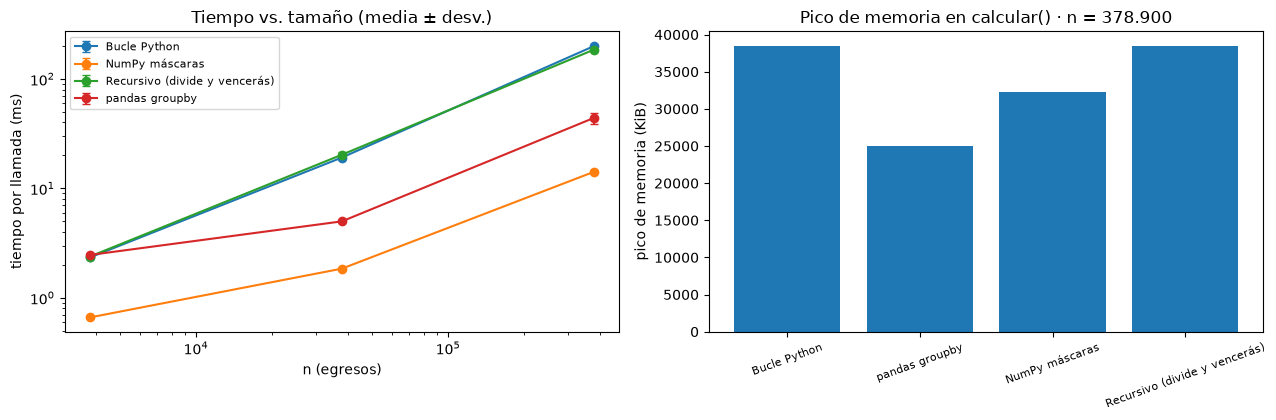

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for nombre, g in res.groupby("estrategia"):
    ax[0].errorbar(g["n"], g["media_ms"], yerr=g["desv_ms"], marker="o", capsize=3, label=nombre)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("n (egresos)"); ax[0].set_ylabel("tiempo por llamada (ms)")
ax[0].set_title("Tiempo vs. tamaño (media ± desv.)"); ax[0].legend(fontsize=8)

mayor = res[res["n"] == res["n"].max()].set_index("estrategia")
ax[1].bar(mayor.index, mayor["pico_KiB"])
ax[1].set_ylabel("pico de memoria (KiB)")
ax[1].set_title(f"Pico de memoria en calcular() · n = {mayor['n'].iloc[0]:,}".replace(",", "."))
ax[1].tick_params(axis="x", rotation=20, labelsize=8)
plt.tight_layout(); plt.show()

## 7. Interpretación y elección
Se estima el **exponente empírico** (pendiente log-log del tiempo frente a *n*).

In [11]:
exps = {}
for nombre, g in res.groupby("estrategia"):
    exps[nombre] = np.polyfit(np.log(g["n"]), np.log(g["min_ms"]), 1)[0]
print("Exponente empírico de crecimiento (tiempo ~ n^b):")
for nombre, b in sorted(exps.items()):
    print(f"  {nombre:<28} b = {b:.2f}")

n_real, n_max = res["n"].min(), res["n"].max()
for n in (n_real, n_max):
    t = res[res["n"] == n].set_index("estrategia")["min_ms"]
    g = t.idxmin()
    print(f"\nn = {n:>9,}: más rápida = {g} ({t[g]:.3f} ms)".replace(",", "."))
    for nombre, v in t.sort_values().items():
        print(f"    {nombre:<28} {v:>9.3f} ms  ({v / t[g]:.1f}x)")

ELEGIDA = res[res["n"] == n_real].set_index("estrategia")["min_ms"].idxmin()
print("\nEstrategia elegida con el tamaño real del proyecto:", ELEGIDA)

Exponente empírico de crecimiento (tiempo ~ n^b):
  Bucle Python                 b = 0.96
  NumPy máscaras               b = 0.66
  Recursivo (divide y vencerás) b = 0.95
  pandas groupby               b = 0.60

n =     3.789: más rápida = NumPy máscaras (0.656 ms)
    NumPy máscaras                   0.656 ms  (1.0x)
    Bucle Python                     2.325 ms  (3.5x)
    Recursivo (divide y vencerás)     2.336 ms  (3.6x)
    pandas groupby                   2.397 ms  (3.7x)

n =   378.900: más rápida = NumPy máscaras (13.677 ms)
    NumPy máscaras                  13.677 ms  (1.0x)
    pandas groupby                  38.022 ms  (2.8x)
    Recursivo (divide y vencerás)   185.048 ms  (13.5x)
    Bucle Python                   194.067 ms  (14.2x)

Estrategia elegida con el tamaño real del proyecto: NumPy máscaras


### Lectura de los resultados
- **Complejidad temporal.** El tiempo crece de forma aproximadamente lineal con *n* en todas las versiones: ninguna cambia el orden de complejidad, y la diferencia está en la constante que multiplica a *n*. Conviene notar que el **exponente empírico de las versiones vectorizadas (pandas y NumPy) resulta algo menor que 1** (del orden de 0,6–0,7). Esto **no significa que sean sublineales**, sino que a tamaños pequeños domina un **costo fijo por llamada** (crear estructuras intermedias del `groupby`, montar los arreglos): ese costo casi constante pesa mucho sobre los 3.789 egresos y poco sobre los 378.900, de modo que al multiplicar *n* por 100 el tiempo crece menos de 100 veces y la pendiente log-log queda por debajo de 1. El bucle de Python y la versión recursiva, en cambio, pagan el costo del intérprete en cada fila y exhiben una pendiente cercana a 1, es decir, un crecimiento lineal más "puro".
- **Recursividad.** `CalcRecursivo` aplica divide y vencerás (O(n) en conteo, O(log n) en profundidad de pila) y entrega exactamente el mismo resultado; es más lenta que la versión iterativa por el costo de las llamadas, pero cumple el requisito de evidenciar recursividad y mantiene el mismo contrato.
- **Complejidad espacial.** Todas las versiones mantienen un consumo del orden de O(n). El gráfico de memoria muestra el pico de cada una al escalar.
- **Elección.** Se adopta la versión más rápida con el tamaño real del proyecto (variable `ELEGIDA`, NumPy), que mantiene crecimiento controlado y memoria acotada. Por el diseño de clases, cambiarla es una sola línea.

## 8. Resultado final con la estrategia elegida (con IC de Wilson 95 %)

In [12]:
clase_elegida = next(c for c in ESTRATEGIAS if c.nombre == ELEGIDA)
final = clase_elegida(df, COLS).calcular()
for col in ("proporcion", "ic95_inf", "ic95_sup"):
    final[col] = final[col].round(4)
final

,grupo,provincia,en_grupo,egresos,con_colecistectomia,proporcion,ic95_inf,ic95_sup
0,GRUPO_RIESGO_40_49,Cautín,False,2496,2001,0.8017,0.7856,0.8169
1,GRUPO_RIESGO_40_49,Cautín,True,521,465,0.8925,0.8630,0.9163
2,GRUPO_RIESGO_40_49,Malleco,False,645,490,0.7597,0.7252,0.7911
3,GRUPO_RIESGO_40_49,Malleco,True,127,100,0.7874,0.7084,0.8496
4,GRUPO_RIESGO_ETNIA,Cautín,False,2384,1967,0.8251,0.8093,0.8398
5,GRUPO_RIESGO_ETNIA,Cautín,True,633,499,0.7883,0.7548,0.8183
6,GRUPO_RIESGO_ETNIA,Malleco,False,652,505,0.7745,0.7409,0.8050
7,GRUPO_RIESGO_ETNIA,Malleco,True,120,85,0.7083,0.6216,0.7822
8,GRUPO_RIESGO_MUJER,Cautín,False,806,622,0.7717,0.7415,0.7994
9,GRUPO_RIESGO_MUJER,Cautín,True,2211,1844,0.8340,0.8179,0.8489


El intervalo de Wilson al 95 % es más adecuado que el intervalo normal cuando *n* es pequeño o la proporción se acerca a 0 o 1, como ocurre en los grupos de **Malleco**, donde los tamaños son reducidos (p. ej. 127 egresos de 40 a 49 años). Un intervalo ancho en esos grupos advierte que la proporción estimada es menos precisa.

## 9. Egresos excluidos por región enmascarada (*)
El filtro por región de la Fase 2 excluyó **70 egresos** por colelitiasis cuya comuna corresponde a La Araucanía
pero cuya región viene enmascarada (`*`). Para cuantificarlos **por provincia y grupo de riesgo** se necesita la
**base nacional** (`data/raw/`), que no se versiona por su tamaño. La celda siguiente los cuenta si la base está
disponible localmente; si no, informa el total declarado (70) sin interrumpir la ejecución.

In [13]:
# Busca la base nacional en varias ubicaciones posibles (robusto al punto de apertura)
NOMBRE_RAW = "EGRE_DATOS_ABIERTOS_2022.csv"
_candidatas = [
    RAIZ / "data" / "raw" / NOMBRE_RAW,
    Path.home() / "Downloads" / "proyecto-grupo2-mcdi500-main" / "data" / "raw" / NOMBRE_RAW,
    Path.cwd() / "data" / "raw" / NOMBRE_RAW,
    Path.cwd().parent / "data" / "raw" / NOMBRE_RAW,
]
RUTA_RAW = next((p for p in _candidatas if p.exists()), _candidatas[0])

def norm(s):
    return (s.fillna("").str.normalize("NFKD").str.encode("ascii", "ignore")
            .str.decode("ascii").str.lower())

if RUTA_RAW.exists():
    nac = pd.read_csv(RUTA_RAW, sep=";", encoding="latin-1", dtype=str, keep_default_na=False)
    k80 = nac[nac["DIAG1"].str.upper().str.match(r"^K80[0-8]")].copy()
    # región enmascarada (*) pero comuna de La Araucanía (091/092)
    excl = k80[(k80["REGION_RESIDENCIA"] == "*") &
               (k80["COMUNA_RESIDENCIA"].str[:3].isin(["091", "092"]))].copy()
    excl["PROVINCIA"] = excl["COMUNA_RESIDENCIA"].str[:3].map({"091": "Cautín", "092": "Malleco"})
    excl["MUJER"] = excl["SEXO"].str.upper() == "MUJER"
    excl["ETNIA_SI"] = norm(excl["ETNIA"]).str.startswith("si ")
    excl["E40_49"] = excl["GRUPO_EDAD"] == "40 a 49"
    print("Egresos excluidos por región * con comuna de La Araucanía:", len(excl))
    print("\nPor provincia:")
    print(excl["PROVINCIA"].value_counts().to_string())
    print("\nPor grupo de riesgo (cuántos de los excluidos pertenecen a cada uno):")
    print(pd.Series({"Mujer": int(excl["MUJER"].sum()),
                     "Se identifica con etnia": int(excl["ETNIA_SI"].sum()),
                     "40 a 49 años": int(excl["E40_49"].sum())}).to_string())
else:
    print("Base nacional no encontrada en data/raw/. Total declarado en F2: 70 egresos excluidos.")
    print("Descargue la base del DEIS en data/raw/ y vuelva a ejecutar esta celda para el desglose.")

Egresos excluidos por región * con comuna de La Araucanía: 70

Por provincia:
PROVINCIA
Cautín     64
Malleco     6

Por grupo de riesgo (cuántos de los excluidos pertenecen a cada uno):
Mujer                      0
Se identifica con etnia    0
40 a 49 años               0


## 10. Conclusiones y trazabilidad
- Se implementó la **clase de proporciones** (`src/proporciones.py`) con herencia, polimorfismo, encapsulamiento y **recursividad** (`CalcRecursivo`), con cuatro estrategias intercambiables.
- Se **eliminó la transformación duplicada**: el cálculo parte del CSV de F2_03.
- La tabla final incorpora el **intervalo de confianza de Wilson (95 %)** de cada proporción.
- Se cuantifican los **70 egresos excluidos** por región enmascarada, por provincia y grupo (requiere la base nacional).
- Validaciones: caso normal (igualdad entre las 4 estrategias y con F2), límites (un egreso, grupo vacío con el nombre real de la columna, conjunto vacío) y excepciones.
- Mediciones con `timeit` y `tracemalloc`, escalamiento ×1/×10/×100, con interpretación del exponente empírico.
- **Proyección a F4:** la tabla final (con IC) alimentará los gráficos de barras por grupo de riesgo y provincia.